# SpuCoMNIST: ERM and Group Balancing

Run the cells from top to bottom. Both models train for 10 epochs. Clustering uses the final ERM features. Training correlation strength is 0.99.

In [2]:
%pip install spuco


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=e7f3191a2909205cf964ef9147b4197116e581667fa054ef568b431fcc140b1a
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [spuco]


In [3]:
import math
import random
import torch
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from torch.utils.data import DataLoader, Subset
from spuco.datasets import SpuCoMNIST, SpuriousFeatureDifficulty
from spuco.models import model_factory
from spuco.group_inference import GeorgeInference
from spuco.utils import set_seed

set_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)


/usr/local/lib/python3.13/dist-packages/outdated/__init__.py:36: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


cuda


## 1. Data

In [4]:
from spuco.datasets import SpuCoMNIST, SpuriousFeatureDifficulty
from spuco.utils import set_seed
set_seed(0)
classes = [[0, 1], [2, 3], [4, 5], [6, 7], [8, 9]]
difficulty = SpuriousFeatureDifficulty.MAGNITUDE_LARGE
trainset = SpuCoMNIST(root='/content/data', spurious_feature_difficulty=difficulty, classes=classes, spurious_correlation_strength=0.99, split='train')
trainset.initialize()
(image, label) = trainset[0]
print('Training samples:', len(trainset))
print('Image shape:', image.shape)
print('Label:', label)
print('Number of classes:', trainset.num_classes)


100%|██████████| 9.91M/9.91M [00:00<00:00, 13.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 347kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.27MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 20.2MB/s]


Training samples: 48004
Image shape: torch.Size([3, 28, 28])
Label: 2
Number of classes: 5


In [5]:
valset = SpuCoMNIST(root='/content/data', spurious_feature_difficulty=difficulty, classes=classes, split='val')
valset.initialize()
testset = SpuCoMNIST(root='/content/data', spurious_feature_difficulty=difficulty, classes=classes, split='test')
testset.initialize()
print('Validation samples:', len(valset))
print('Test samples:', len(testset))


Validation samples: 11996
Test samples: 10000


In [6]:
train_loader = DataLoader(trainset, batch_size=64, shuffle=True)
feature_loader = DataLoader(trainset, batch_size=64, shuffle=False)
loss_fn = torch.nn.CrossEntropyLoss()


## 2. Evaluation

In [7]:
def evaluate(model, dataset):
    model.eval()
    group_accuracies = {}
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for group, indices in sorted(dataset.group_partition.items()):
            loader = DataLoader(Subset(dataset, indices), batch_size=256)
            correct = 0
            total = 0

            for images, labels in loader:
                images = images.to(device)
                labels = labels.to(device)
                predictions = model(images).argmax(dim=1)
                correct += (predictions == labels).sum().item()
                total += labels.size(0)

            group_accuracies[group] = 100 * correct / total
            total_correct += correct
            total_samples += total

    accuracy = 100 * total_correct / total_samples
    worst_accuracy = min(group_accuracies.values())
    return accuracy, worst_accuracy, group_accuracies


## 3. ERM

In [8]:
model = model_factory(
    arch="lenet",
    input_shape=(3, 28, 28),
    num_classes=5,
    pretrained=False,
).to(device)

optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
erm_history = []


In [9]:
erm_epochs = 10

for epoch in range(erm_epochs):
    model.train()
    total_loss = 0
    total_correct = 0
    total_samples = 0

    for images, labels in tqdm(train_loader, desc=f"ERM epoch {epoch + 1}"):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += labels.size(0)

    val_accuracy, worst_accuracy, erm_groups = evaluate(model, valset)
    result = {
        "epoch": len(erm_history) + 1,
        "train_loss": total_loss / total_samples,
        "train_accuracy": 100 * total_correct / total_samples,
        "val_accuracy": val_accuracy,
        "worst_group_accuracy": worst_accuracy,
    }
    erm_history.append(result)
    print(result)


ERM epoch 1:   0%|          | 0/751 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.6527463611179345, 'train_accuracy': 81.80568285976169, 'val_accuracy': 19.99833277759253, 'worst_group_accuracy': 0.0}


ERM epoch 2:   0%|          | 0/751 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.0823407222287671, 'train_accuracy': 98.9938338471794, 'val_accuracy': 19.99833277759253, 'worst_group_accuracy': 0.0}


ERM epoch 3:   0%|          | 0/751 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 0.0757752321875481, 'train_accuracy': 98.9938338471794, 'val_accuracy': 19.99833277759253, 'worst_group_accuracy': 0.0}


... (10 outputs left out)

ERM epoch 9:   0%|          | 0/751 [00:00<?, ?it/s]

{'epoch': 9, 'train_loss': 0.06897756977731767, 'train_accuracy': 98.9938338471794, 'val_accuracy': 19.99833277759253, 'worst_group_accuracy': 0.0}


ERM epoch 10:   0%|          | 0/751 [00:00<?, ?it/s]

{'epoch': 10, 'train_loss': 0.06874404816262243, 'train_accuracy': 98.9938338471794, 'val_accuracy': 19.99833277759253, 'worst_group_accuracy': 0.0}


## 4. Learning curves

,epoch,train_loss,train_accuracy,val_accuracy,worst_group_accuracy
0,1,0.652746,81.805683,19.998333,0.0
1,2,0.082341,98.993834,19.998333,0.0
2,3,0.075775,98.993834,19.998333,0.0
3,4,0.072598,98.993834,19.998333,0.0
4,5,0.070871,98.993834,19.998333,0.0
5,6,0.070208,98.993834,19.998333,0.0
6,7,0.069604,98.993834,19.998333,0.0
7,8,0.069292,98.993834,19.998333,0.0
8,9,0.068978,98.993834,19.998333,0.0
9,10,0.068744,98.993834,19.998333,0.0


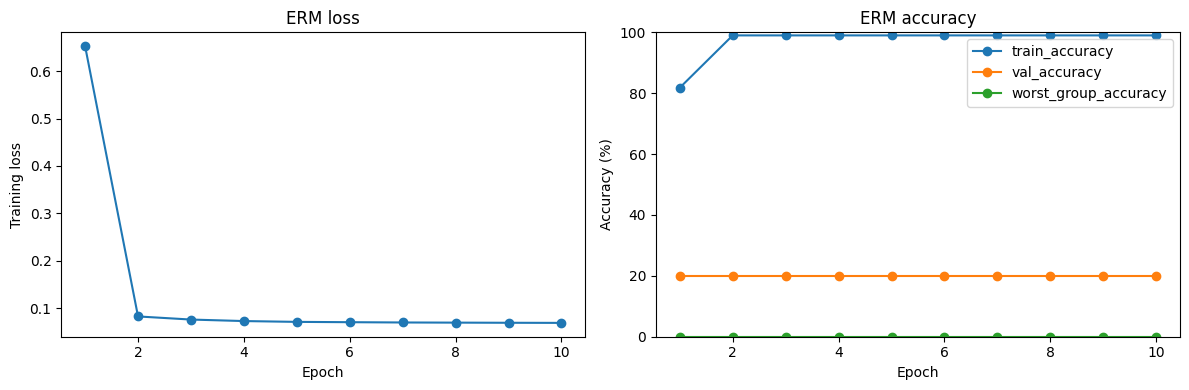

In [10]:
def plot_history(history, title):
    results = pd.DataFrame(history)
    display(results)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(results["epoch"], results["train_loss"], marker="o")
    axes[0].set_title(title + " loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Training loss")

    for metric in ["train_accuracy", "val_accuracy", "worst_group_accuracy"]:
        axes[1].plot(results["epoch"], results[metric], marker="o", label=metric)

    axes[1].set_title(title + " accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].set_ylim(0, 100)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(erm_history, "ERM")


## 5. Features and clustering

In [11]:
model.eval()
feature_batches = []

with torch.no_grad():
    for images, labels in feature_loader:
        features = model.backbone(images.to(device))
        feature_batches.append(features.cpu())

train_features = torch.cat(feature_batches, dim=0)
print(train_features.shape)


torch.Size([48004, 84])


In [12]:
group_infer = GeorgeInference(
    Z=train_features,
    class_labels=trainset.labels,
    max_clusters=5,
    verbose=True,
)

inferred_groups = group_infer.infer_groups()
print("Number of groups:", len(inferred_groups))

for group, indices in sorted(inferred_groups.items()):
    print(group, len(indices))


Clustering class-wise: 100%|██████████| 5/5 [00:20<00:00,  4.15s/it]

Number of groups: 18
(0, 0) 3010
(0, 1) 454
(0, 2) 1679
(0, 3) 3735
(0, 4) 1255
(1, 0) 2833
(1, 1) 1182
(1, 2) 400
(1, 3) 5257
(2, 0) 8920
(2, 1) 91
(3, 0) 4816
(3, 1) 105
(3, 2) 2123
(3, 3) 308
(3, 4) 2395
(4, 0) 95
(4, 1) 9346


## 6. Balanced training

In [13]:
def draw_balanced_batch(group_partition, samples_per_group):
    batch_indices = []
    for indices in group_partition.values():
        batch_indices.extend(random.choices(indices, k=samples_per_group))
    return batch_indices


In [14]:
balanced_model = model_factory(
    arch="lenet",
    input_shape=(3, 28, 28),
    num_classes=5,
    pretrained=False,
).to(device)

balanced_optimizer = torch.optim.SGD(balanced_model.parameters(), lr=0.01)
balanced_history = []


In [15]:
balanced_epochs = 10
samples_per_group = 2
balanced_batch_size = len(inferred_groups) * samples_per_group
steps_per_epoch = math.ceil(len(trainset) / balanced_batch_size)

print("ERM updates per epoch:", len(train_loader))
print("Balanced updates per epoch:", steps_per_epoch)

for epoch in range(balanced_epochs):
    balanced_model.train()
    total_loss = 0
    total_correct = 0
    total_samples = 0

    for step in tqdm(range(steps_per_epoch), desc=f"Balanced epoch {epoch + 1}"):
        batch_indices = draw_balanced_batch(inferred_groups, samples_per_group)
        batch_loader = DataLoader(
            Subset(trainset, batch_indices),
            batch_size=len(batch_indices),
            shuffle=False,
        )
        images, labels = next(iter(batch_loader))
        images = images.to(device)
        labels = labels.to(device)

        balanced_optimizer.zero_grad()
        logits = balanced_model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        balanced_optimizer.step()

        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += labels.size(0)

    val_accuracy, worst_accuracy, balanced_groups = evaluate(balanced_model, valset)
    result = {
        "epoch": len(balanced_history) + 1,
        "train_loss": total_loss / total_samples,
        "train_accuracy": 100 * total_correct / total_samples,
        "val_accuracy": val_accuracy,
        "worst_group_accuracy": worst_accuracy,
    }
    balanced_history.append(result)
    print(result)


ERM updates per epoch: 751
Balanced updates per epoch: 1334


Balanced epoch 1:   0%|          | 0/1334 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.7895579874470853, 'train_accuracy': 74.62935199067132, 'val_accuracy': 20.840280093364456, 'worst_group_accuracy': 0.0}


Balanced epoch 2:   0%|          | 0/1334 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.4449926806555159, 'train_accuracy': 85.03248375812095, 'val_accuracy': 32.01900633544515, 'worst_group_accuracy': 0.0}


Balanced epoch 3:   0%|          | 0/1334 [00:00<?, ?it/s]

... (11 outputs left out)

Balanced epoch 9:   0%|          | 0/1334 [00:00<?, ?it/s]

{'epoch': 9, 'train_loss': 0.024525598107170938, 'train_accuracy': 99.44194569381976, 'val_accuracy': 63.246082027342446, 'worst_group_accuracy': 7.6604554865424435}


Balanced epoch 10:   0%|          | 0/1334 [00:00<?, ?it/s]

{'epoch': 10, 'train_loss': 0.021723057559985114, 'train_accuracy': 99.45860403131768, 'val_accuracy': 63.97132377459153, 'worst_group_accuracy': 14.285714285714286}


,epoch,train_loss,train_accuracy,val_accuracy,worst_group_accuracy
0,1,0.789558,74.629352,20.840280,0.000000
1,2,0.444993,85.032484,32.019006,0.000000
2,3,0.263203,90.773363,47.857619,0.000000
3,4,0.153081,94.898384,55.710237,0.000000
4,5,0.090456,97.136848,59.078026,0.828157
5,6,0.057442,98.402882,57.744248,0.000000
6,7,0.036405,99.079627,59.461487,0.000000
7,8,0.029024,99.329502,63.187729,9.523810
8,9,0.024526,99.441946,63.246082,7.660455
9,10,0.021723,99.458604,63.971324,14.285714


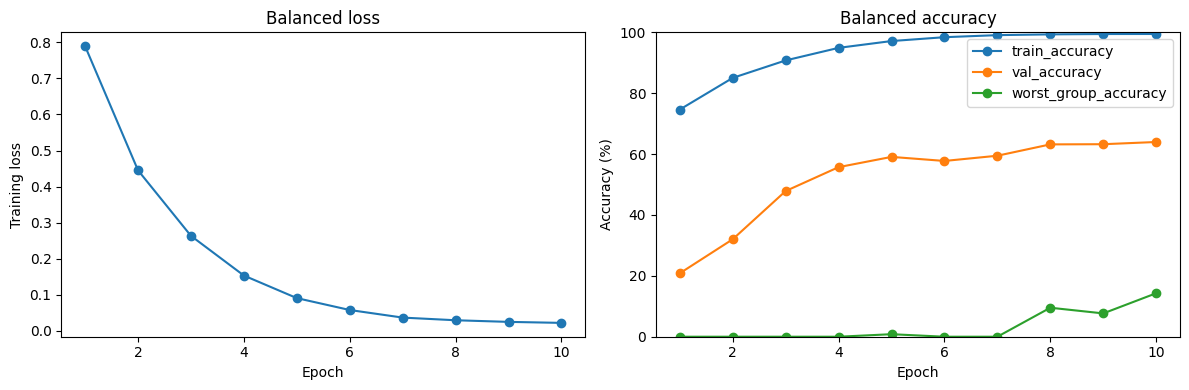

In [16]:
plot_history(balanced_history, "Balanced")


## 7. Validation group results

In [17]:
group_results = pd.DataFrame({
    "ERM": pd.Series(erm_groups),
    "Balanced": pd.Series(balanced_groups),
})
group_results.index.names = ["class", "spurious_group"]
display(group_results)


ERM   Balanced
class spurious_group                  
0     0               100.0  99.802761
      1                 0.0  40.039448
      2                 0.0  32.608696
      3                 0.0  15.019763
      4                 0.0  35.573123
1     0                 0.0  65.289256
      1               100.0  99.380165
      2                 0.0  50.931677
      3                 0.0  14.285714
      4                 0.0  25.465839
2     0                 0.0  67.849224
      1                 0.0  70.509978
      2               100.0  99.555556
      3                 0.0  53.777778
      4                 0.0  65.555556
3     0                 0.0  80.737705
      1                 0.0  72.073922
      2                 0.0  73.511294
      3               100.0  99.794661
      4                 0.0  77.002053
4     0                 0.0  80.720339
      1                 0.0  57.203390
      2                 0.0  60.381356
      3                 0.0  70.338983
      4               100.0  99.363057

In [18]:
true_background = {}

for group, indices in trainset.group_partition.items():
    for index in indices:
        true_background[index] = group[1]

rows = []

for group, indices in sorted(inferred_groups.items()):
    backgrounds = [true_background[index] for index in indices]
    counts = pd.Series(backgrounds).value_counts()

    row = {
        "class": group[0],
        "cluster": group[1],
        "size": len(indices),
    }

    for background in range(5):
        row[f"background_{background}"] = counts.get(background, 0)

    rows.append(row)

display(pd.DataFrame(rows))

,class,cluster,size,background_0,background_1,background_2,background_3,background_4
0,0,0,3010,2947,30,13,0,20
1,0,1,454,454,0,0,0,0
2,0,2,1679,1679,0,0,0,0
3,0,3,3735,3696,0,11,28,0
4,0,4,1255,1255,0,0,0,0
5,1,0,2833,32,2736,24,23,18
6,1,1,1182,0,1182,0,0,0
7,1,2,400,0,400,0,0,0
8,1,3,5257,0,5257,0,0,0
9,2,0,8920,0,0,8920,0,0


## 8. Conclusion
I first trained an ERM model, then grouped the images using the features it learned. Next, I trained a new model with the same number of images from each group in every batch.

The original model relied heavily on background colors. It predicted correctly when the background matched the usual color for the class, but failed when the background changed. After group-balanced training, performance improved across all mismatched-background groups. The worst-group accuracy increased from 0% to 14.29%.

However, some images with uncommon backgrounds remained inside large groups and were rarely sampled. The method helped, but the model was still affected by background colors.

